# Stable Diffusion 1.5 · Imagen a imagen

Prueba de viabilidad para PlanIA P2. El notebook recibe una imagen y un prompt, genera una variación y mide la memoria de GPU utilizada.

En Kaggle abre **Edit**, selecciona una **GPU T4** en **Accelerator** y activa **Internet** para descargar las dependencias y los pesos. Puedes usar **Run All** con el ejemplo incorporado. Para usar una imagen propia, adjúntala con **Add Input** y ajusta la ruta y el prompt en el paso 2.

[Guía de Diffusers](https://huggingface.co/docs/diffusers/using-diffusers/img2img) · [Ficha de Stable Diffusion 1.5](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

## 1. Instalar dependencias

Usamos el PyTorch con CUDA que ya incluye Kaggle y fijamos las versiones de las librerías de inferencia.

In [1]:
%pip install -q diffusers==0.35.2 transformers==4.57.1 accelerate==1.11.0

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## 2. Elegir la imagen y el prompt

Deja **image_path** en **None** para usar el dibujo de ejemplo. Para usar una imagen propia (JPG o PNG), adjúntala en Kaggle y copia su ruta bajo **/kaggle/input/** en **image_path**. Escribe en **prompt** el resultado que quieres obtener.

**strength** controla cuánto cambia la imagen. Un valor menor conserva más del original. La semilla permite repetir la prueba con la misma configuración.

In [2]:
image_path = None  # Por ejemplo, "/kaggle/input/mis-fotos/flor.jpg"
prompt = "A botanical watercolor painting of a pink cosmos flower, textured ivory paper, delicate brushwork"
strength = 0.65
num_inference_steps = 25
guidance_scale = 7.5
seed = 42

## 3. Preparar la entrada y comprobar la GPU

El ejemplo es un dibujo creado con Pillow. Para archivos propios, se respeta la orientación y se ajusta la imagen a 512 × 512 con relleno para conservar las proporciones. La prueba usa la primera GPU que PyTorch detecta.

In [3]:
import json
from importlib.metadata import version
from math import cos, sin, tau
from pathlib import Path
from time import perf_counter

import torch
from diffusers import StableDiffusionImg2ImgPipeline
from IPython.display import display
from PIL import Image, ImageDraw, ImageOps

if not torch.cuda.is_available():
    raise RuntimeError("Activa una GPU en Settings → Accelerator y ejecuta de nuevo.")

device = torch.device("cuda:0")
gpu = torch.cuda.get_device_properties(device)
gib = 1024**3
print(f"GPU: {gpu.name} | VRAM visible para PyTorch: {gpu.total_memory / gib:.2f} GiB")

if image_path is None:
    input_image = Image.new("RGB", (512, 512), "#f8f2e7")
    draw = ImageDraw.Draw(input_image)
    draw.line((256, 216, 240, 455), fill="#497342", width=14)
    draw.ellipse((138, 339, 246, 390), fill="#658d51")
    for petal in range(8):
        angle = petal * tau / 8
        x = 256 + 77 * cos(angle)
        y = 214 + 77 * sin(angle)
        draw.ellipse((x - 46, y - 46, x + 46, y + 46), fill="#e883a5", outline="#bb4a73", width=3)
    draw.ellipse((219, 177, 293, 251), fill="#e7ad3d", outline="#ab6829", width=4)
else:
    with Image.open(image_path) as source:
        oriented = ImageOps.exif_transpose(source).convert("RGB")
        input_image = ImageOps.pad(oriented, (512, 512), Image.Resampling.LANCZOS, color="#f8f2e7")

output_dir = Path("/kaggle/working")
input_image.save(output_dir / "entrada.png")

I0000 00:00:1793996696.208730      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


GPU: Tesla T4 | VRAM visible para PyTorch: 14.56 GiB


## 4. Cargar Stable Diffusion 1.5

Descargamos una revisión fija del modelo y la cargamos en la GPU en precisión FP16 para reducir el uso de VRAM. La primera descarga puede tardar varios minutos.

In [4]:
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
model_revision = "451f4fe16113bff5a5d2269ed5ad43b0592e9a14"

torch.cuda.reset_peak_memory_stats(device)
load_start = perf_counter()
pipeline = StableDiffusionImg2ImgPipeline.from_pretrained(
    model_id,
    revision=model_revision,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True,
)
pipeline.to(device)
pipeline.set_progress_bar_config(disable=True)
torch.cuda.synchronize(device)
load_seconds = perf_counter() - load_start

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

... (8 outputs left out)

unet/diffusion_pytorch_model.fp16.safete(…):   0%|          | 0.00/1.72G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.fp16.safeten(…):   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


## 5. Generar y guardar una variación

La imagen y el prompt guían la generación. Guardamos la entrada preparada, la variación y un JSON con los parámetros, el tiempo y el pico de memoria de PyTorch durante la carga y la generación. El tiempo de generación se mide por separado.

En una sesión interactiva encontrarás los archivos en **/kaggle/working**. Para conservarlos en la pestaña **Output**, usa **Save Version → Save & Run All**.

Generación: 11.81 s | Pico asignado: 3.18 GiB
Entrada a la izquierda y variación generada a la derecha.


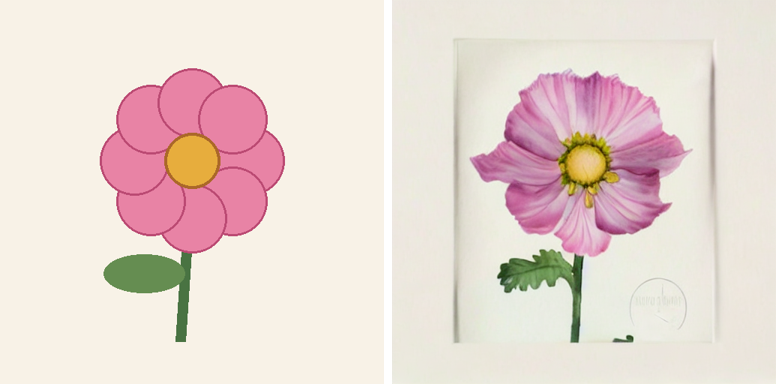

In [5]:
generator = torch.Generator(device=device).manual_seed(seed)

generation_start = perf_counter()
result = pipeline(
    prompt=prompt,
    image=input_image,
    strength=strength,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    generator=generator,
)
torch.cuda.synchronize(device)
generation_seconds = perf_counter() - generation_start

generated_image = result.images[0]
generated_image.save(output_dir / "generada.png")

summary = {
    "status": "complete",
    "stage": "done",
    "model": model_id,
    "revision": model_revision,
    "dtype": "float16",
    "gpu": gpu.name,
    "gpu_count": torch.cuda.device_count(),
    "vram_total_gib": round(gpu.total_memory / gib, 2),
    "vram_peak_allocated_gib": round(torch.cuda.max_memory_allocated(device) / gib, 2),
    "vram_peak_reserved_gib": round(torch.cuda.max_memory_reserved(device) / gib, 2),
    "load_seconds": round(load_seconds, 2),
    "generation_seconds": round(generation_seconds, 2),
    "versions": {name: version(name) for name in ("torch", "diffusers", "transformers", "accelerate")},
    "input_source": image_path or "dibujo de ejemplo",
    "size_px": list(generated_image.size),
    "prompt": prompt,
    "strength": strength,
    "num_inference_steps": num_inference_steps,
    "guidance_scale": guidance_scale,
    "seed": seed,
    "safety_flagged": bool(result.nsfw_content_detected and result.nsfw_content_detected[0]),
    "artifacts": ["entrada.png", "generada.png", "run_summary.json"],
}
(output_dir / "run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

print(f"Generación: {generation_seconds:.2f} s | Pico asignado: {summary['vram_peak_allocated_gib']:.2f} GiB")
print("Entrada a la izquierda y variación generada a la derecha.")
preview = Image.new("RGB", (776, 384), "white")
preview.paste(input_image.resize((384, 384)), (0, 0))
preview.paste(generated_image.resize((384, 384)), (392, 0))
display(preview)